In [1]:
import numpy as np

docs = ['go india',
		'india india',
		'hip hip hurray',
		'jeetega bhai jeetega india jeetega',
		'bharat mata ki jai',
		'kohli kohli',
		'sachin sachin',
		'dhoni dhoni',
		'modi ji ki jai',
		'inquilab zindabad']

### Text to Numbers

In [2]:
from tensorflow.keras.preprocessing.text import Tokenizer
tokenizer = Tokenizer()

### Assigns higher priority (smaller numbers) to more frequent words

In [3]:
tokenizer.fit_on_texts(docs)

In [6]:
len(tokenizer.word_index)

17

In [7]:
sequences = tokenizer.texts_to_sequences(docs)
sequences

[[9, 1],
 [1, 1],
 [3, 3, 10],
 [2, 11, 2, 1, 2],
 [12, 13, 4, 5],
 [6, 6],
 [7, 7],
 [8, 8],
 [14, 15, 4, 5],
 [16, 17]]

### Add Padding

In [8]:
from keras.utils import pad_sequences
sequences = pad_sequences(sequences, padding='post')
sequences

array([[ 9,  1,  0,  0,  0],
       [ 1,  1,  0,  0,  0],
       [ 3,  3, 10,  0,  0],
       [ 2, 11,  2,  1,  2],
       [12, 13,  4,  5,  0],
       [ 6,  6,  0,  0,  0],
       [ 7,  7,  0,  0,  0],
       [ 8,  8,  0,  0,  0],
       [14, 15,  4,  5,  0],
       [16, 17,  0,  0,  0]], dtype=int32)

In [12]:
from keras import Sequential
from keras.layers import Input, Dense, Embedding, SimpleRNN, Flatten

In [14]:
model = Sequential()

model.add(Embedding(18, output_dim=2, input_length=5))
model.build(input_shape = (None, 5))

c:\Users\M Arshad\.conda\envs\deep\lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [15]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 5, 2)           │            36 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 36 (144.00 B)

 Trainable params: 36 (144.00 B)

 Non-trainable params: 0 (0.00 B)

In [16]:
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

In [17]:
pred = model.predict(sequences)
print(pred)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step
[[[-0.00578449 -0.04736374]
  [-0.01163974 -0.01599174]
  [ 0.00156188 -0.00621029]
  [ 0.00156188 -0.00621029]
  [ 0.00156188 -0.00621029]]

 [[-0.01163974 -0.01599174]
  [-0.01163974 -0.01599174]
  [ 0.00156188 -0.00621029]
  [ 0.00156188 -0.00621029]
  [ 0.00156188 -0.00621029]]

 [[ 0.03855318 -0.00894814]
  [ 0.03855318 -0.00894814]
  [-0.03403359 -0.04010947]
  [ 0.00156188 -0.00621029]
  [ 0.00156188 -0.00621029]]

 [[ 0.03098028  0.04942787]
  [-0.01854784 -0.00499099]
  [ 0.03098028  0.04942787]
  [-0.01163974 -0.01599174]
  [ 0.03098028  0.04942787]]

 [[-0.00295988 -0.02004947]
  [-0.00324016  0.0272642 ]
  [ 0.00081872 -0.00915767]
  [ 0.03679924  0.01924575]
  [ 0.00156188 -0.00621029]]

 [[-0.02055699  0.0419299 ]
  [-0.02055699  0.0419299 ]
  [ 0.00156188 -0.00621029]
  [ 0.00156188 -0.00621029]
  [ 0.00156188 -0.00621029]]

 [[ 0.00022946 -0.0495212 ]
  [ 0.00022946 -0.0495212 ]
  [ 0.00156188 -0.00621029]
  [ 0.00156188 -0.00621029

## Mini Project Using Embadding

In [35]:
from keras.datasets import imdb
(x_train, y_train), (x_test, y_test) = imdb.load_data(
    path = 'E:/Deep Learning/DL/RNN/Sentiment Analysis/imdb.npz',
    num_words=10000
)

In [36]:
x_train = pad_sequences(x_train, padding='post', maxlen = 50)
x_test = pad_sequences(x_test, padding='post', maxlen=50)

In [38]:
model = Sequential()

# model.add(Input(shape=(50,)))
model.add(Embedding(10000, 2, input_length=50))
model.add(SimpleRNN(32, return_sequences=False))
model.add(Dense(1, activation='sigmoid'))

In [39]:
model.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_3 (SimpleRNN)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [40]:
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

## Model Training 

In [41]:
history = model.fit(x_train, y_train, epochs=5, validation_data=(x_test, y_test))

Epoch 1/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 15s 16ms/step - accuracy: 0.5333 - loss: 0.6827 - val_accuracy: 0.7687 - val_loss: 0.4892
Epoch 2/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.8094 - loss: 0.4221 - val_accuracy: 0.8046 - val_loss: 0.4272
Epoch 3/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.8642 - loss: 0.3293 - val_accuracy: 0.8103 - val_loss: 0.4320
Epoch 4/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.8895 - loss: 0.2810 - val_accuracy: 0.8050 - val_loss: 0.4454
Epoch 5/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.9071 - loss: 0.2421 - val_accuracy: 0.7897 - val_loss: 0.5104


## Embedding Performance

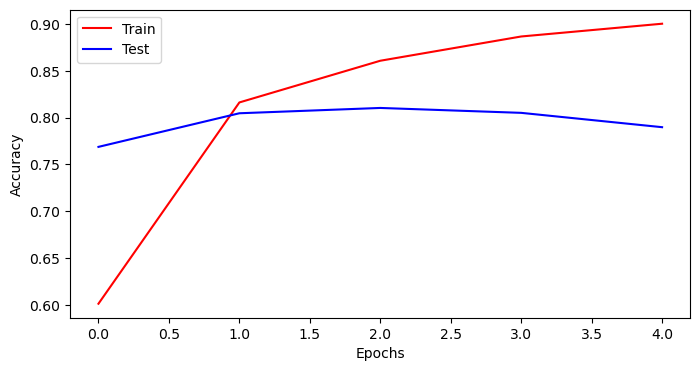

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 4))
plt.plot(history.history['accuracy'], label='Train', color='Red')
plt.plot(history.history['val_accuracy'], label='Test', color='blue')

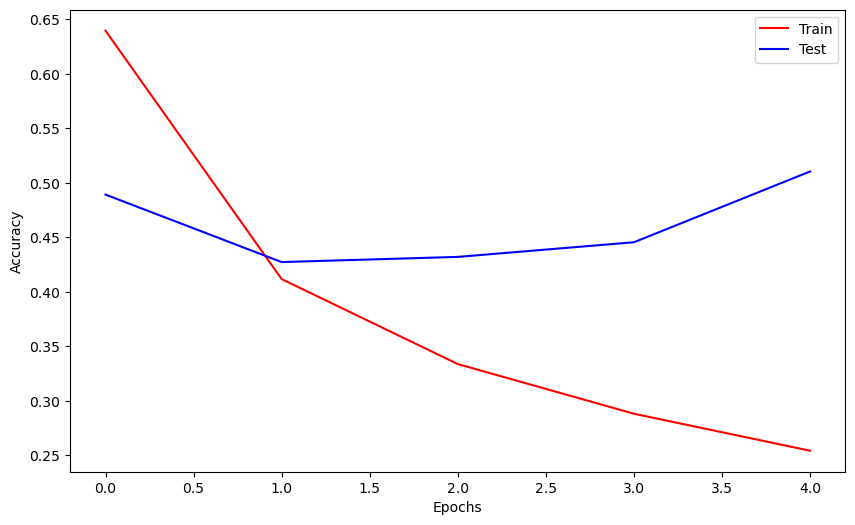

In [43]:
plt.figure(figsize=(10, 6))
plt.plot(history.history['loss'], label='Train', color='Red')
plt.plot(history.history['val_loss'], label='Test', color='blue')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()